In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/data.csv", sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4424
Number of columns: 37


In [5]:
for i, column in enumerate(df.columns, 1):
    print(i, column)

1 Marital status
2 Application mode
3 Application order
4 Course
5 Daytime/evening attendance	
6 Previous qualification
7 Previous qualification (grade)
8 Nacionality
9 Mother's qualification
10 Father's qualification
11 Mother's occupation
12 Father's occupation
13 Admission grade
14 Displaced
15 Educational special needs
16 Debtor
17 Tuition fees up to date
18 Gender
19 Scholarship holder
20 Age at enrollment
21 International
22 Curricular units 1st sem (credited)
23 Curricular units 1st sem (enrolled)
24 Curricular units 1st sem (evaluations)
25 Curricular units 1st sem (approved)
26 Curricular units 1st sem (grade)
27 Curricular units 1st sem (without evaluations)
28 Curricular units 2nd sem (credited)
29 Curricular units 2nd sem (enrolled)
30 Curricular units 2nd sem (evaluations)
31 Curricular units 2nd sem (approved)
32 Curricular units 2nd sem (grade)
33 Curricular units 2nd sem (without evaluations)
34 Unemployment rate
35 Inflation rate
36 GDP
37 Target


In [6]:
print(df["Target"].value_counts())

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [7]:
print(df["Target"].value_counts(normalize=True) * 100)

Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [10]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder               

In [11]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


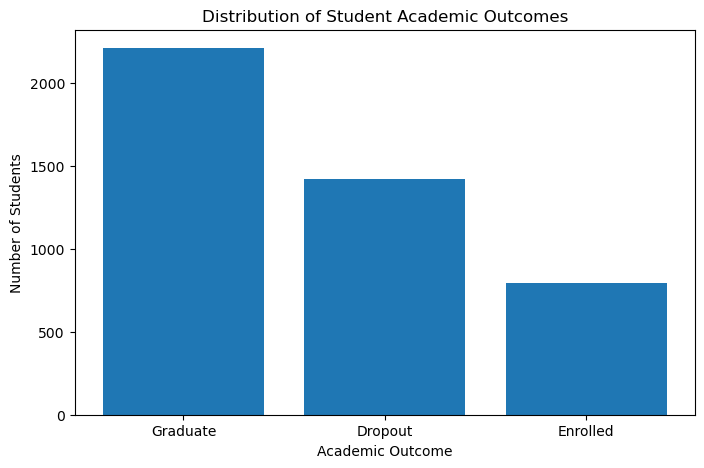

In [13]:
target_counts = df["Target"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(target_counts.index, target_counts.values)

plt.title("Distribution of Student Academic Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")

plt.show()

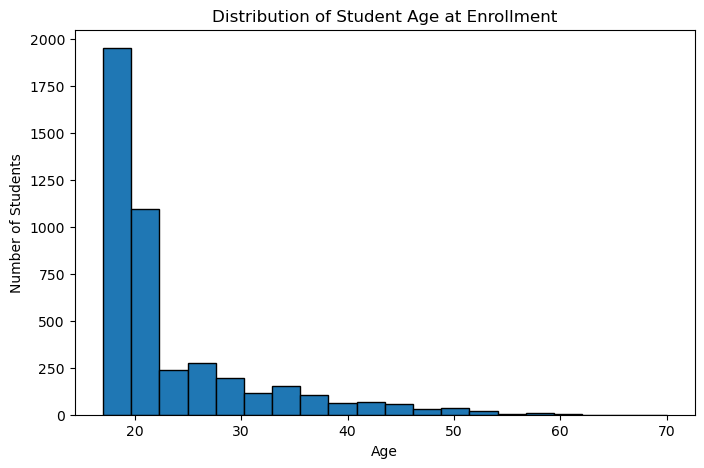

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age at enrollment"], bins=20, edgecolor="black")

plt.title("Distribution of Student Age at Enrollment")
plt.xlabel("Age")
plt.ylabel("Number of Students")

plt.show()

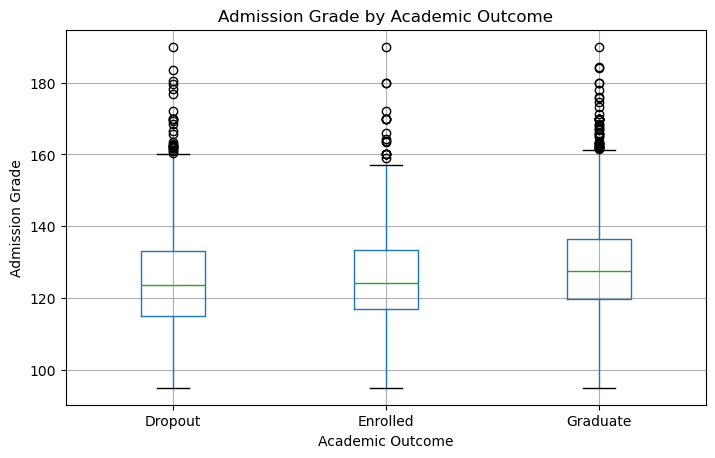

In [15]:
df.boxplot(
    column="Admission grade",
    by="Target",
    figsize=(8, 5)
)

plt.title("Admission Grade by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Admission Grade")

plt.show()

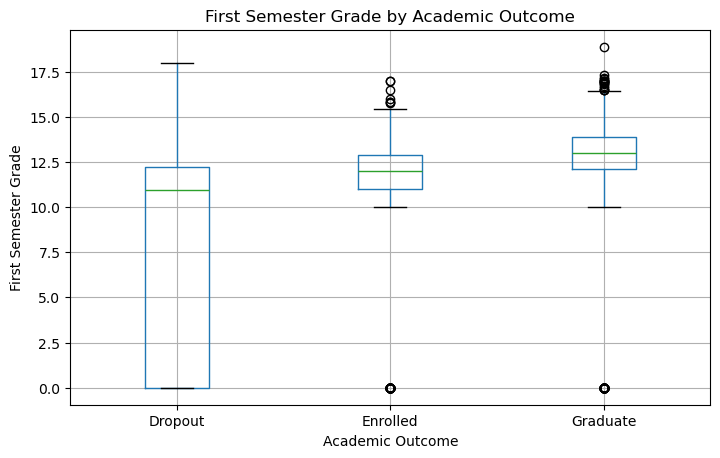

In [16]:
df.boxplot(
    column="Curricular units 1st sem (grade)",
    by="Target",
    figsize=(8, 5)
)

plt.title("First Semester Grade by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("First Semester Grade")

plt.show()

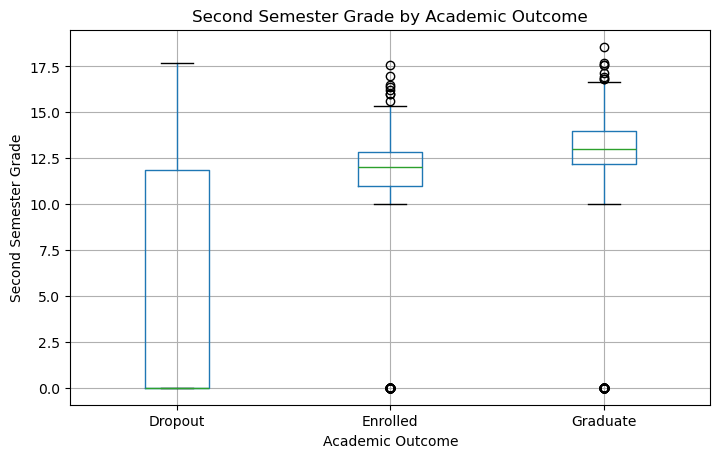

In [17]:
df.boxplot(
    column="Curricular units 2nd sem (grade)",
    by="Target",
    figsize=(8, 5)
)

plt.title("Second Semester Grade by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Second Semester Grade")

plt.show()

In [18]:
df.columns = df.columns.str.strip()

print("Column names cleaned successfully!")

Column names cleaned successfully!


In [19]:
print(df.columns.tolist())

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [20]:
X = df.drop("Target", axis=1)
y = df["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4424, 36)
y shape: (4424,)


In [21]:
categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("Original number of features:", X.shape[1])
print("Features after encoding:", X_encoded.shape[1])

Original number of features: 36
Features after encoding: 255


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 3539
Testing samples: 885


In [23]:
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
Target
Graduate    49.929359
Dropout     32.127720
Enrolled    17.942922
Name: proportion, dtype: float64

Testing distribution:
Target
Graduate    49.943503
Dropout     32.090395
Enrolled    17.966102
Name: proportion, dtype: float64


In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed!
Training shape: (3539, 255)
Testing shape: (885, 255)


In [25]:
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_logistic[:10])

Predictions completed!

First 10 actual values:
['Graduate' 'Graduate' 'Enrolled' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']

First 10 predicted values:
['Graduate' 'Graduate' 'Dropout' 'Graduate' 'Graduate' 'Dropout'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


In [27]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:")
print(round(logistic_accuracy, 4))

print("\nAccuracy Percentage:")
print(round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy:
0.7458

Accuracy Percentage:
74.58 %


In [28]:
logistic_precision = precision_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

logistic_recall = recall_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.7458
Precision: 0.7308
Recall   : 0.7458
F1 Score : 0.7354


In [29]:
print("Classification Report - Logistic Regression")
print()

print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

Classification Report - Logistic Regression

              precision    recall  f1-score   support

     Dropout       0.76      0.74      0.75       284
    Enrolled       0.48      0.36      0.41       159
    Graduate       0.80      0.89      0.84       442

    accuracy                           0.75       885
   macro avg       0.68      0.66      0.67       885
weighted avg       0.73      0.75      0.74       885



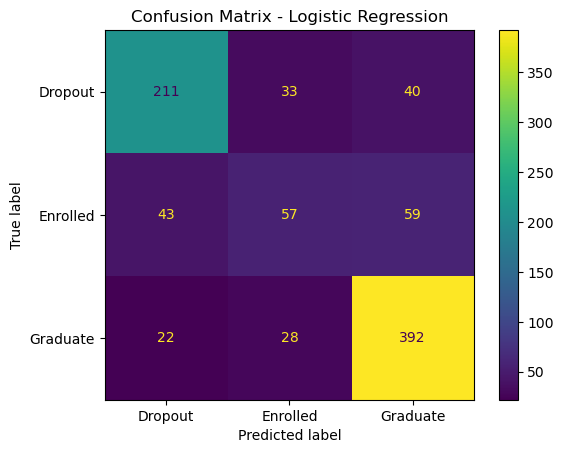

In [30]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=logistic_model.classes_
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [31]:
logistic_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ]
})

logistic_results["Logistic Regression"] = (
    logistic_results["Logistic Regression"] * 100
).round(2)

logistic_results

,Metric,Logistic Regression
0,Accuracy,74.58
1,Precision,73.08
2,Recall,74.58
3,F1 Score,73.54


In [32]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [33]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [34]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

print("Random Forest Performance")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))

Random Forest Performance
--------------------------------
Accuracy : 0.7605
Precision: 0.7416
Recall   : 0.7605
F1 Score : 0.7398


In [35]:
print("Classification Report - Random Forest")
print()

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Classification Report - Random Forest

              precision    recall  f1-score   support

     Dropout       0.80      0.75      0.77       284
    Enrolled       0.55      0.29      0.38       159
    Graduate       0.78      0.94      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.66      0.67       885
weighted avg       0.74      0.76      0.74       885



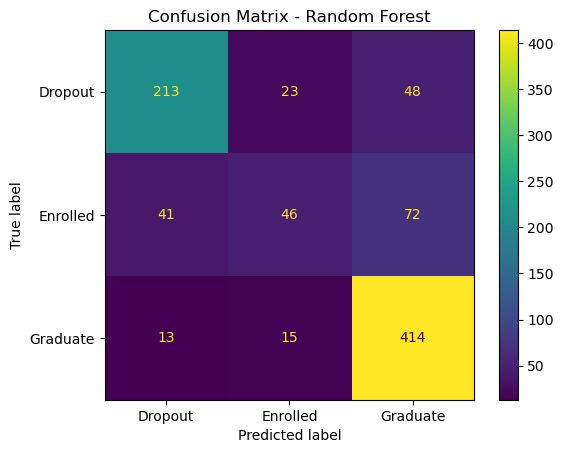

In [36]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=random_forest_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=random_forest_model.classes_
)

disp.plot()

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [37]:
comparison_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ],
    
    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

comparison_results[
    ["Logistic Regression", "Random Forest"]
] = comparison_results[
    ["Logistic Regression", "Random Forest"]
] * 100

comparison_results[
    ["Logistic Regression", "Random Forest"]
] = comparison_results[
    ["Logistic Regression", "Random Forest"]
].round(2)

comparison_results

,Metric,Logistic Regression,Random Forest
0,Accuracy,74.58,76.05
1,Precision,73.08,74.16
2,Recall,74.58,76.05
3,F1 Score,73.54,73.98


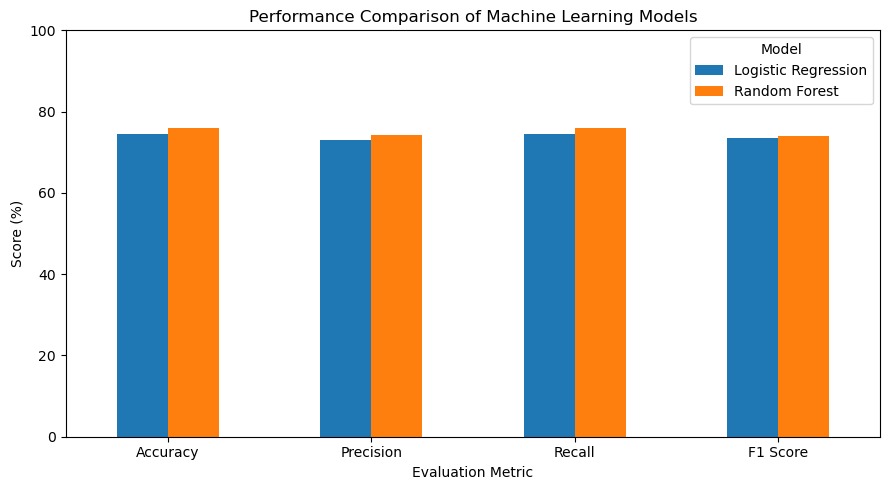

In [38]:
comparison_plot = comparison_results.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

In [39]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
13,Curricular units 2nd sem (approved),0.091449
14,Curricular units 2nd sem (grade),0.075865
7,Curricular units 1st sem (approved),0.061019
8,Curricular units 1st sem (grade),0.054135
12,Curricular units 2nd sem (evaluations),0.039903
6,Curricular units 1st sem (evaluations),0.036978
2,Admission grade,0.035270
3,Age at enrollment,0.033971
1,Previous qualification (grade),0.032892
247,Tuition fees up to date_0,0.024816


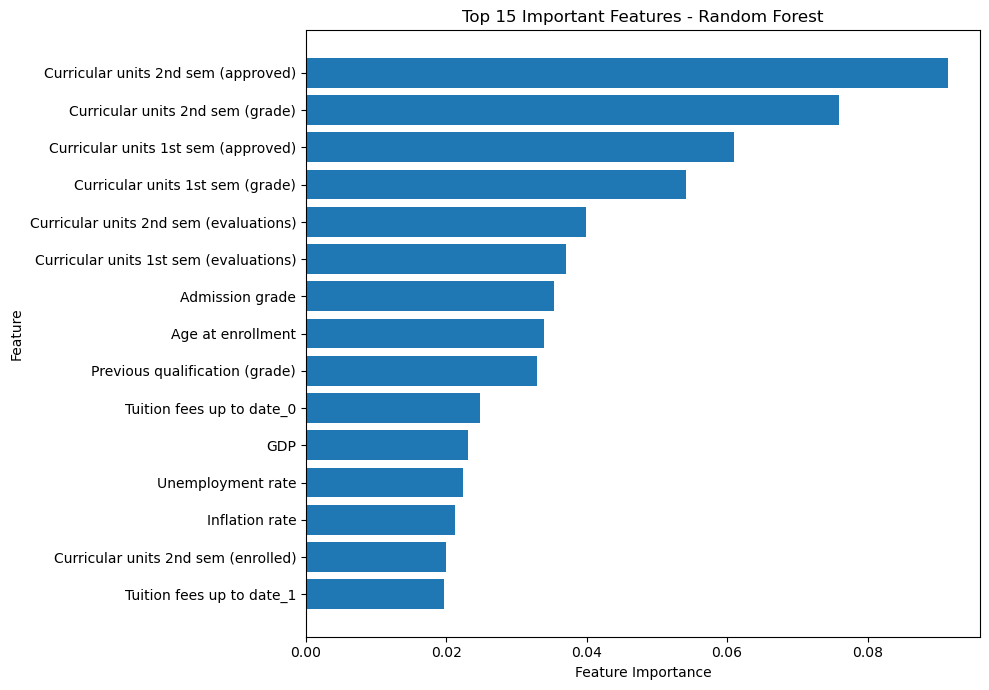

In [40]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [41]:
print("Random Forest Classification Report")
print("-----------------------------------")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report
-----------------------------------
              precision    recall  f1-score   support

     Dropout       0.80      0.75      0.77       284
    Enrolled       0.55      0.29      0.38       159
    Graduate       0.78      0.94      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.66      0.67       885
weighted avg       0.74      0.76      0.74       885



In [42]:
rf_train_predictions = random_forest_model.predict(X_train)

rf_train_accuracy = accuracy_score(
    y_train,
    rf_train_predictions
)

print("Random Forest Training Accuracy:",
      round(rf_train_accuracy * 100, 2), "%")

print("Random Forest Testing Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Training Accuracy: 100.0 %
Random Forest Testing Accuracy: 76.05 %


In [43]:
tuned_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42
)

tuned_rf_model.fit(X_train, y_train)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [44]:
y_pred_tuned_rf = tuned_rf_model.predict(X_test)
y_train_pred_tuned_rf = tuned_rf_model.predict(X_train)

print("Predictions completed!")

Predictions completed!


In [45]:
tuned_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_tuned_rf
)

tuned_test_accuracy = accuracy_score(
    y_test,
    y_pred_tuned_rf
)

print("Tuned Random Forest Training Accuracy:",
      round(tuned_train_accuracy * 100, 2), "%")

print("Tuned Random Forest Testing Accuracy:",
      round(tuned_test_accuracy * 100, 2), "%")

print("Training-Testing Gap:",
      round((tuned_train_accuracy - tuned_test_accuracy) * 100, 2),
      "%")

Tuned Random Forest Training Accuracy: 83.16 %
Tuned Random Forest Testing Accuracy: 74.58 %
Training-Testing Gap: 8.58 %


In [46]:
print("Tuned Random Forest Classification Report")
print("-----------------------------------------")

print(classification_report(
    y_test,
    y_pred_tuned_rf
))

Tuned Random Forest Classification Report
-----------------------------------------
              precision    recall  f1-score   support

     Dropout       0.81      0.69      0.75       284
    Enrolled       0.45      0.62      0.52       159
    Graduate       0.86      0.83      0.84       442

    accuracy                           0.75       885
   macro avg       0.71      0.71      0.70       885
weighted avg       0.77      0.75      0.75       885



In [47]:
tuned_rf_accuracy = accuracy_score(y_test, y_pred_tuned_rf)

tuned_rf_precision = precision_score(
    y_test,
    y_pred_tuned_rf,
    average="weighted"
)

tuned_rf_recall = recall_score(
    y_test,
    y_pred_tuned_rf,
    average="weighted"
)

tuned_rf_f1 = f1_score(
    y_test,
    y_pred_tuned_rf,
    average="weighted"
)

print("Tuned RF Accuracy:", round(tuned_rf_accuracy * 100, 2))
print("Tuned RF Precision:", round(tuned_rf_precision * 100, 2))
print("Tuned RF Recall:", round(tuned_rf_recall * 100, 2))
print("Tuned RF F1 Score:", round(tuned_rf_f1 * 100, 2))

Tuned RF Accuracy: 74.58
Tuned RF Precision: 77.09
Tuned RF Recall: 74.58
Tuned RF F1 Score: 75.43


In [48]:
final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ],

    "Original Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ],

    "Tuned Random Forest": [
        tuned_rf_accuracy,
        tuned_rf_precision,
        tuned_rf_recall,
        tuned_rf_f1
    ]
})

# Convert to percentages
model_columns = [
    "Logistic Regression",
    "Original Random Forest",
    "Tuned Random Forest"
]

final_comparison[model_columns] = (
    final_comparison[model_columns] * 100
).round(2)

final_comparison

,Metric,Logistic Regression,Original Random Forest,Tuned Random Forest
0,Accuracy,74.58,76.05,74.58
1,Precision,73.08,74.16,77.09
2,Recall,74.58,76.05,74.58
3,F1 Score,73.54,73.98,75.43


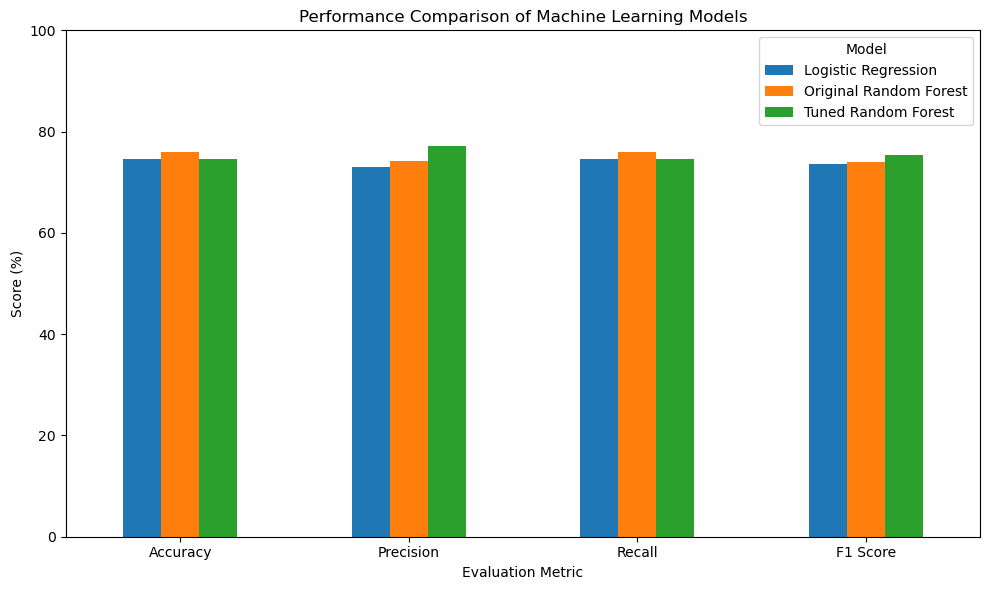

In [49]:
comparison_plot = final_comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

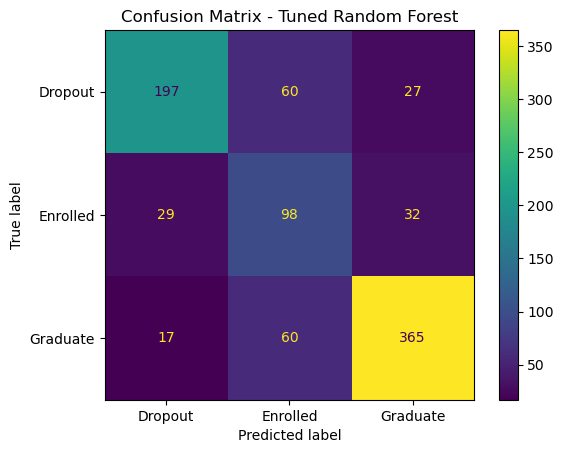

In [50]:
cm_tuned_rf = confusion_matrix(
    y_test,
    y_pred_tuned_rf,
    labels=tuned_rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned_rf,
    display_labels=tuned_rf_model.classes_
)

disp.plot()

plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

In [51]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

print("Models folder ready!")

Models folder ready!


In [52]:
joblib.dump(
    tuned_rf_model,
    "../models/tuned_random_forest.pkl"
)

print("Tuned Random Forest model saved successfully!")

Tuned Random Forest model saved successfully!


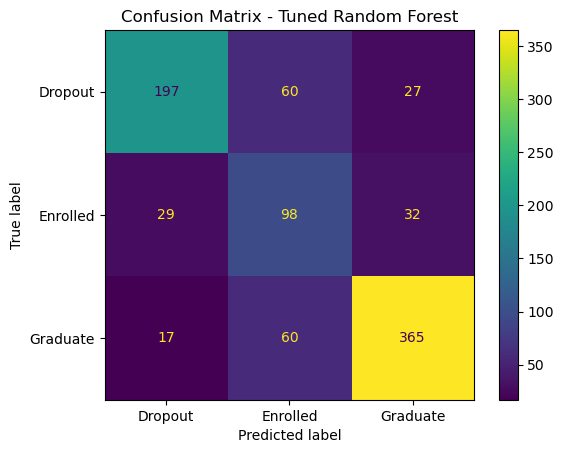

In [53]:
cm_tuned_rf = confusion_matrix(
    y_test,
    y_pred_tuned_rf,
    labels=tuned_rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned_rf,
    display_labels=tuned_rf_model.classes_
)

disp.plot()

plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

In [54]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    tuned_rf_model,
    "../models/tuned_random_forest.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [55]:
print("Scaler:", scaler)

print("\nX_train shape:", X_train.shape)
print("X_train_scaled shape:", X_train_scaled.shape)

print("\nNumber of final features:", X_train.shape[1])

print("\nFirst 20 feature names:")
print(X_train.columns[:20].tolist())

Scaler: StandardScaler()

X_train shape: (3539, 255)
X_train_scaled shape: (3539, 255)

Number of final features: 255

First 20 feature names:
['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Marital status_1']


In [56]:
# Save the fitted scaler
joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

# Save the exact 255 feature names and their order
joblib.dump(
    X_train.columns.tolist(),
    "../models/feature_names.pkl"
)

print("Scaler saved successfully!")
print("Feature names saved successfully!")
print("Number of saved features:", len(X_train.columns))

Scaler saved successfully!
Feature names saved successfully!
Number of saved features: 255


In [57]:
print("Original dataset shape:", df.shape)

print("\nX shape:", X.shape)

print("\nFirst 30 columns of X:")
print(X.columns[:30].tolist())

print("\nData types:")
print(X.dtypes.value_counts())

Original dataset shape: (4424, 37)

X shape: (4424, 36)

First 30 columns of X:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)']

Data types:
int64      29
float64     7
Name: count, dtype: int64


In [58]:
print("X original shape:", X.shape)
print("X_train encoded shape:", X_train.shape)

print("\nOriginal columns:")
print(X.columns.tolist())

print("\nColumns that became dummy/encoded features:")
for col in X.columns:
    matches = [c for c in X_train.columns if c.startswith(str(col) + "_")]
    if len(matches) > 0:
        print(col, "->", len(matches), "encoded columns")

X original shape: (4424, 36)
X_train encoded shape: (3539, 255)

Original columns:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without e

In [59]:
categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

joblib.dump(
    categorical_columns,
    "../models/categorical_columns.pkl"
)

print("Categorical columns saved successfully!")
print("Number of categorical columns:", len(categorical_columns))

Categorical columns saved successfully!
Number of categorical columns: 17


In [60]:
# Select one real student from the original dataset
sample_student = X.iloc[[0]].copy()

print("Original student data shape:", sample_student.shape)

# Convert categorical columns to categorical type
for col in categorical_columns:
    sample_student[col] = sample_student[col].astype(str)

# One-hot encode
sample_encoded = pd.get_dummies(
    sample_student,
    columns=categorical_columns
)

# Make encoded column names strings
sample_encoded.columns = sample_encoded.columns.astype(str)

# Match exactly the 255 columns used during training
sample_encoded = sample_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("After encoding shape:", sample_encoded.shape)

# Predict using final tuned Random Forest
sample_prediction = tuned_rf_model.predict(sample_encoded)

print("\nPredicted outcome:", sample_prediction[0])
print("Actual outcome:", y.iloc[0])

Original student data shape: (1, 36)
After encoding shape: (1, 255)

Predicted outcome: Dropout
Actual outcome: Dropout


In [61]:
# Test the model with several students

test_indices = [0, 10, 50, 100, 500]

print("MODEL PREDICTION TEST")
print("=" * 60)

for i in test_indices:

    student = X.iloc[[i]].copy()

    # Convert categorical values to strings
    for col in categorical_columns:
        student[col] = student[col].astype(str)

    # One-hot encoding
    student_encoded = pd.get_dummies(
        student,
        columns=categorical_columns
    )

    student_encoded.columns = student_encoded.columns.astype(str)

    # Match the exact training features
    student_encoded = student_encoded.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Prediction
    prediction = tuned_rf_model.predict(student_encoded)[0]

    # Actual value
    actual = y.iloc[i]

    print("Student:", i)
    print("Predicted:", prediction)
    print("Actual:", actual)

    if prediction == actual:
        print("Result: CORRECT ✓")
    else:
        print("Result: INCORRECT ✗")

    print("-" * 60)

MODEL PREDICTION TEST
Student: 0
Predicted: Dropout
Actual: Dropout
Result: CORRECT ✓
------------------------------------------------------------
Student: 10
Predicted: Graduate
Actual: Graduate
Result: CORRECT ✓
------------------------------------------------------------
Student: 50
Predicted: Graduate
Actual: Graduate
Result: CORRECT ✓
------------------------------------------------------------
Student: 100
Predicted: Graduate
Actual: Dropout
Result: INCORRECT ✗
------------------------------------------------------------
Student: 500
Predicted: Enrolled
Actual: Enrolled
Result: CORRECT ✓
------------------------------------------------------------


In [62]:
def predict_student(student_data):
    """
    Predict student outcome:
    Dropout, Enrolled, or Graduate
    """

    # Convert input dictionary to DataFrame
    student_df = pd.DataFrame([student_data])

    # Convert categorical columns to string
    for col in categorical_columns:
        student_df[col] = student_df[col].astype(str)

    # One-hot encode categorical columns
    student_encoded = pd.get_dummies(
        student_df,
        columns=categorical_columns
    )

    # Make column names strings
    student_encoded.columns = student_encoded.columns.astype(str)

    # Match exactly the 255 features used during training
    student_encoded = student_encoded.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Make prediction
    prediction = tuned_rf_model.predict(student_encoded)[0]

    return prediction


print("Prediction function created successfully!")

Prediction function created successfully!


In [63]:
# Take one real student for testing
test_student = X.iloc[10].to_dict()

# Use our new prediction function
result = predict_student(test_student)

print("Predicted student outcome:", result)
print("Actual student outcome:", y.iloc[10])

Predicted student outcome: Graduate
Actual student outcome: Graduate


In [64]:
import os

print("Files inside models folder:")
print(os.listdir("../models"))

Files inside models folder:
['scaler.pkl', 'categorical_columns.pkl', 'tuned_random_forest.pkl', 'feature_names.pkl']


In [65]:
import joblib

joblib.dump(
    X.columns.tolist(),
    "../models/input_columns.pkl"
)

print("Input columns saved!")
print("Number of input columns:", len(X.columns))

Input columns saved!
Number of input columns: 36


In [66]:
category_values = {}

for col in categorical_columns:
    category_values[col] = sorted(
        X[col].dropna().unique().tolist()
    )

joblib.dump(
    category_values,
    "../models/category_values.pkl"
)

print("Category values saved successfully!")

for col, values in category_values.items():
    print(col, ":", values)

Category values saved successfully!
Marital status : [1, 2, 3, 4, 5, 6]
Application mode : [1, 2, 5, 7, 10, 15, 16, 17, 18, 26, 27, 39, 42, 43, 44, 51, 53, 57]
Course : [33, 171, 8014, 9003, 9070, 9085, 9119, 9130, 9147, 9238, 9254, 9500, 9556, 9670, 9773, 9853, 9991]
Daytime/evening attendance : [0, 1]
Previous qualification : [1, 2, 3, 4, 5, 6, 9, 10, 12, 14, 15, 19, 38, 39, 40, 42, 43]
Nacionality : [1, 2, 6, 11, 13, 14, 17, 21, 22, 24, 25, 26, 32, 41, 62, 100, 101, 103, 105, 108, 109]
Mother's qualification : [1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 14, 18, 19, 22, 26, 27, 29, 30, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]
Father's qualification : [1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 13, 14, 18, 19, 20, 22, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]
Mother's occupation : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 90, 99, 122, 123, 125, 131, 132, 134, 141, 143, 144, 151, 152, 153, 171, 173, 175, 191, 192, 193, 194]
Father's occupation : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10,

In [67]:
import os
print(os.getcwd())

/Users/anjalikiriella/Documents/MSc/Fundamentals of Machine Learning/Student_Dropout_ML_Project/notebooks
